In [1]:
#pip uninstall torch-geometric torch-scatter torch-sparse torch-cluster torch-spline-conv -y

In [2]:
#from IPython.core.display import HTML
#HTML("<script>Jupyter.notebook.kernel.restart()</script>")

In [3]:
#pip install torch-geometric

In [4]:
#from IPython.core.display import HTML
#HTML("<script>Jupyter.notebook.kernel.restart()</script>")

In [5]:
import pandas as pd
import numpy as np
import torch
from torch_geometric.data import HeteroData
import torch_geometric.transforms as T
import numpy as np
from sklearn.model_selection import train_test_split

In [6]:
df_fase1=pd.read_csv('/kaggle/input/datasets/nico14h/metagenomica/dataset.csv', sep='\t')
print(df_fase1)

                       Bacteria_Limpia       Paciente  AbundanciaTaxonomica  \
0                          Akkermansia  SRR10442269_1             -2.663544   
1                         Anaerostipes  SRR10442269_1              0.044506   
2                          Bacteroides  SRR10442269_1              3.197242   
3                      Bifidobacterium  SRR10442269_1              2.215463   
4                              Blautia  SRR10442269_1              2.386312   
...                                ...            ...                   ...   
10788   [Eubacterium]_ventriosum_group  SRR10442395_1             -1.322955   
10789  [Ruminococcus]_gauvreauii_group  SRR10442395_1              0.597114   
10790      [Ruminococcus]_gnavus_group  SRR10442395_1              2.849783   
10791     [Ruminococcus]_torques_group  SRR10442395_1              3.462451   
10792                       uncultured  SRR10442395_1             -0.260710   

       paciente_id  bacteria_id  Diagnosticos  
0  

In [7]:
import torch
from torch_geometric.data import HeteroData
import torch_geometric.transforms as T
import numpy as np

# ==========================================
# 1. INICIALIZAR EL GRAFO (HETERODATA)
# ==========================================
data = HeteroData()
num_pacientes = df_fase1['paciente_id'].max() + 1
num_bacterias = df_fase1['bacteria_id'].max() + 1

# NUEVA LÓGICA: Pacientes como "pizarra en blanco". 
# Les damos un vector neutral de 16 dimensiones llenas de '1s'.
dim_oculta_inicial = 16
data['paciente'].x = torch.ones((num_pacientes, dim_oculta_inicial), dtype=torch.float)

# A las bacterias sí les dejamos el One-Hot, porque funcionan como un "diccionario universal"
data['bacteria'].x = torch.eye(num_bacterias, dtype=torch.float)

# ==========================================
# 2. CONEXIONES (ARISTAS) Y PESOS (CLR)
# ==========================================
df_conexiones_reales = df_fase1[df_fase1['AbundanciaTaxonomica'] != 0.0]
origen = torch.tensor(df_conexiones_reales['paciente_id'].values, dtype=torch.long)
destino = torch.tensor(df_conexiones_reales['bacteria_id'].values, dtype=torch.long)
data['paciente', 'abundancia_de', 'bacteria'].edge_index = torch.stack([origen, destino], dim=0)

# Las abundancias ahora contienen los valores rCLR (positivos y negativos)
data['paciente', 'abundancia_de', 'bacteria'].edge_attr = torch.tensor(
    df_conexiones_reales['AbundanciaTaxonomica'].values, dtype=torch.float
).unsqueeze(1)

num_aristas = data['paciente', 'abundancia_de', 'bacteria'].edge_index.shape[1]
print(f"Cantidad total de aristas en el grafo: {num_aristas}")
# ==========================================
# 3. ETIQUETAS Y MÁSCARAS BLINDADAS
# ==========================================
df_etiquetas = df_fase1[['paciente_id', 'Diagnosticos']].drop_duplicates().sort_values('paciente_id')
tensor_y = torch.zeros(num_pacientes, dtype=torch.long)

for _, fila in df_etiquetas.iterrows():
    tensor_y[int(fila['paciente_id'])] = int(fila['Diagnosticos'])

data['paciente'].y = tensor_y

# Direccionalidad del grafo
data = T.ToUndirected()(data)

print("Grafo inicializado exitosamente con vectores neutrales (Sin PCA).")
print(f"Dimensiones de las características de pacientes (x): {data['paciente'].x.shape}")

Cantidad total de aristas en el grafo: 10793
Grafo inicializado exitosamente con vectores neutrales (Sin PCA).
Dimensiones de las características de pacientes (x): torch.Size([121, 16])


In [8]:
import numpy as np
import torch

# Obtenemos la cantidad total de pacientes
num_pacientes = data['paciente'].num_nodes

# Inicializamos tensores booleanos en False
train_mask = torch.zeros(num_pacientes, dtype=torch.bool)
test_mask = torch.zeros(num_pacientes, dtype=torch.bool)

indices = np.arange(num_pacientes)
etiquetas = data['paciente'].y.numpy()

# Separar los índices según la clase real
indices_hc = indices[etiquetas == 0]
indices_tea = indices[etiquetas == 1]

# ELECCIÓN ALEATORIA EXACTA: 40 HC y 56 TEA
np.random.seed(42) # Semilla para que los resultados sean constantes en tu tesis
train_hc = np.random.choice(indices_hc, size=40, replace=False)
train_tea = np.random.choice(indices_tea, size=56, replace=False)

# Unimos para formar la bolsa de entrenamiento de 96 pacientes
train_idx = np.concatenate([train_hc, train_tea])

# Los pacientes restantes (121 - 96 = 25) van a la bolsa de Test/Validación
test_idx = np.setdiff1d(indices, train_idx)

# Activamos las máscaras
train_mask[train_idx] = True
test_mask[test_idx] = True

data['paciente'].train_mask = train_mask
data['paciente'].test_mask = test_mask

print(f"Bolsa de Entrenamiento: {len(train_idx)} pacientes ({len(train_hc)} HC, {len(train_tea)} TEA)")
print(f"Bolsa de Validación/Test: {len(test_idx)} pacientes")

Bolsa de Entrenamiento: 96 pacientes (40 HC, 56 TEA)
Bolsa de Validación/Test: 25 pacientes


In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATv2Conv, HeteroConv

class GAT_Neurodesarrollo(nn.Module):
    def __init__(self, hidden_channels, out_channels, edge_types, num_classes, num_bacterias): 
        super().__init__()

        conv1_dict = {}
        conv2_dict = {}
        for edge_type in edge_types:
            # GATv2Conv aprovecha mucho mejor el edge_attr (rCLR) que GATConv clásico
            conv1_dict[edge_type] = GATv2Conv(
                (-1, -1), hidden_channels, add_self_loops=False, heads=2, concat=False, edge_dim=1
            )
            conv2_dict[edge_type] = GATv2Conv(
                (-1, -1), out_channels, add_self_loops=False, heads=1, concat=False, edge_dim=1
            )

        self.conv1 = HeteroConv(conv1_dict, aggr='mean')
        self.conv2 = HeteroConv(conv2_dict, aggr='mean')

        # Usamos Linear normal (no Lazy) pasándole num_bacterias para evitar errores al cambiar canales
        self.lin_bacteria = nn.Linear(num_bacterias, hidden_channels)

        # CRÍTICO: LayerNorm estabiliza la escala sin importar qué hidden_channels u out_channels elijas
        self.norm_p1 = nn.LayerNorm(hidden_channels)
        self.norm_b1 = nn.LayerNorm(hidden_channels)
        self.norm_p2 = nn.LayerNorm(out_channels)

        self.dropout = nn.Dropout(p=0.4)
        self.clasificador = nn.Linear(hidden_channels + out_channels, num_classes)

    def forward(self, x_dict, edge_index_dict, edge_attr_dict):
        identidad_bacteria = self.lin_bacteria(x_dict['bacteria'])

        # --- PRIMER SALTO ---
        x_dict_1 = self.conv1(x_dict, edge_index_dict, edge_attr_dict=edge_attr_dict)
        
        # Normalizamos con LayerNorm antes de activar: evita que los pacientes colapsen al mismo valor
        x_p1 = F.elu(self.norm_p1(x_dict_1['paciente']))
        x_b1 = F.elu(self.norm_b1(x_dict_1['bacteria'] + identidad_bacteria))

        x_dict_intermedio = {
            'paciente': self.dropout(x_p1),
            'bacteria': self.dropout(x_b1)
        }

        # --- SEGUNDO SALTO ---
        x_dict_2 = self.conv2(x_dict_intermedio, edge_index_dict, edge_attr_dict=edge_attr_dict)
        x_p2 = F.elu(self.norm_p2(x_dict_2['paciente']))

        # --- CLASIFICACIÓN ---
        x_pacientes_final = torch.cat([x_p1, x_p2], dim=-1)
        salida = self.clasificador(x_pacientes_final)
        return salida

# Obtenemos el número exacto de bacterias del grafo
num_bacterias = data['bacteria'].x.shape[1]
tipos_aristas = data.metadata()[1]

# Ahora puedes cambiar hidden_channels y out_channels al valor que quieras sin que colapse:
modelo = GAT_Neurodesarrollo(
    hidden_channels=8, 
    out_channels=4, 
    edge_types=tipos_aristas, 
    num_classes=2,
    num_bacterias=num_bacterias
)
print("¡Modelo GATv2 + LayerNorm instanciado correctamente!")

¡Modelo GATv2 + LayerNorm instanciado correctamente!


Pesos calculados automáticamente (HC, TEA): [1.2        0.85714286]

--- INICIANDO ENTRENAMIENTO DE GAT (2 CAPAS) ---
Época 050 | Pérdida (Loss): 0.6529
Época 100 | Pérdida (Loss): 0.3760
Época 150 | Pérdida (Loss): 0.1987
Época 200 | Pérdida (Loss): 0.1221
Época 250 | Pérdida (Loss): 0.0782
Época 300 | Pérdida (Loss): 0.0456

--- INICIANDO EVALUACIÓN EN CONJUNTO DE PRUEBA ---

REPORTE DE CLASIFICACIÓN:
               precision    recall  f1-score   support

 Clase 0 (HC)       0.86      0.60      0.71        10
Clase 1 (TEA)       0.78      0.93      0.85        15

     accuracy                           0.80        25
    macro avg       0.82      0.77      0.78        25
 weighted avg       0.81      0.80      0.79        25



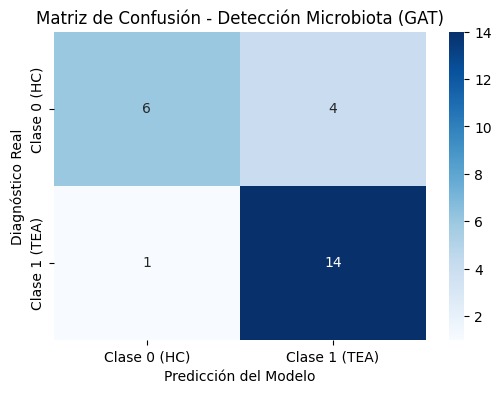

In [10]:
import torch.optim as optim
import torch.nn as nn
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# ==========================================
# 1. PREPARACIÓN DEL ENTORNO Y DATOS
# ==========================================
# Mandamos el modelo y los datos a la placa de video (GPU) si está disponible
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
modelo = modelo.to(device)
data = data.to(device)

# Aislamos las etiquetas reales y la máscara de entrenamiento ANTES de calcular los pesos
etiquetas_reales = data['paciente'].y
mascara_train = data['paciente'].train_mask

# ==========================================
# 2. INICIALIZACIÓN PEREZOSA Y AJUSTE DE PESOS
# ==========================================
# !!! LA SOLUCIÓN AL ERROR !!!
# Pase de prueba (Dummy pass) para que el modelo construya sus tensores
# antes de enviárselos al optimizador.
with torch.no_grad():
    modelo(data.x_dict, data.edge_index_dict, data.edge_attr_dict)

# Calcula pesos matemáticamente exactos basados en el conjunto de entrenamiento
pesos_calculados = compute_class_weight(
    class_weight='balanced', 
    classes=np.array([0, 1]), 
    y=etiquetas_reales[mascara_train].cpu().numpy()
)
pesos_clases = torch.tensor(pesos_calculados, dtype=torch.float).to(device)

print(f"Pesos calculados automáticamente (HC, TEA): {pesos_calculados}")

# Función de pérdida con los pesos dinámicos inyectados
criterio = nn.CrossEntropyLoss(weight=pesos_clases)

# AHORA SÍ: El optimizador puede recibir los parámetros porque ya están inicializados
optimizador = optim.AdamW(modelo.parameters(), lr=0.0005, weight_decay=5e-4)

# ==========================================
# 3. BUCLE DE ENTRENAMIENTO ESTABILIZADO
# ==========================================
epocas = 300
print("\n--- INICIANDO ENTRENAMIENTO DE GAT (2 CAPAS) ---")

for epoca in range(epocas):
    modelo.train()
    optimizador.zero_grad()

    # Forward Pass (Propagamos TODA la información por el grafo)
    salida = modelo(data.x_dict, data.edge_index_dict, data.edge_attr_dict)

    # Cálculo de Error (Loss) SOLO sobre los pacientes de entrenamiento
    loss = criterio(salida[mascara_train], etiquetas_reales[mascara_train])
    loss.backward()

    # Gradient Clipping: Clava los gradientes para que no exploten
    torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)

    optimizador.step()

    if (epoca + 1) % 50 == 0:
        print(f'Época {epoca+1:03d} | Pérdida (Loss): {loss.item():.4f}')

# ==========================================
# 4. EVALUACIÓN Y REPORTE VISUAL
# ==========================================
print("\n--- INICIANDO EVALUACIÓN EN CONJUNTO DE PRUEBA ---")
modelo.eval()

with torch.no_grad():
    salida_final = modelo(data.x_dict, data.edge_index_dict, data.edge_attr_dict)
    clases_predichas = salida_final.argmax(dim=1)

mascara_test = data['paciente'].test_mask
y_real = etiquetas_reales[mascara_test].cpu().numpy()
y_predicho = clases_predichas[mascara_test].cpu().numpy()

nombres_clases = ['Clase 0 (HC)', 'Clase 1 (TEA)']

print("\nREPORTE DE CLASIFICACIÓN:")
print(classification_report(y_real, y_predicho, target_names=nombres_clases))

matriz = confusion_matrix(y_real, y_predicho)
plt.figure(figsize=(6, 4))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=nombres_clases,
            yticklabels=nombres_clases)
plt.title('Matriz de Confusión - Detección Microbiota (GAT)')
plt.ylabel('Diagnóstico Real')
plt.xlabel('Predicción del Modelo')
plt.show()

In [11]:
import pandas as pd
import torch

print("--- INICIANDO EXPLICABILIDAD (EXTRACCIÓN DE ATENCIÓN) ---")

# 1. Elegir un paciente para analizar (como antes)
mascara_test = data['paciente'].test_mask
pacientes_test_idx = mascara_test.nonzero(as_tuple=True)[0]

# Tomamos el primer paciente de test como ejemplo
paciente_objetivo = pacientes_test_idx[0].item()
diagnostico_real = data['paciente'].y[paciente_objetivo].item()
print(f"Analizando Paciente ID Interno: {paciente_objetivo} | Diagnóstico real: {diagnostico_real}")

# =========================================================
# EL TRUCO DE LA ATENCIÓN: Extraer los pesos directamente
# =========================================================
# En lugar de usar GNNExplainer, le pedimos a tu capa GATConv
# que nos devuelva exactamente cuánta "atención" (importancia)
# le prestó a cada conexión durante el último salto.

tipo_arista = ('paciente', 'abundancia_de', 'bacteria')
conexiones = data.edge_index_dict[tipo_arista]

modelo.eval()
with torch.no_grad():
    # Accedemos a la capa específica dentro del HeteroConv
    capa_gat = modelo.conv1.convs[tipo_arista]

    # x_tupla: (características de origen, características de destino)
    x_tupla = (data.x_dict['paciente'], data.x_dict['bacteria'])

    # Hacemos una pasada por esta única capa pidiéndole que DEVUELVA LOS PESOS DE ATENCIÓN (return_attention_weights=True)
    out, (edge_index_out, alpha) = capa_gat(
        x_tupla,
        conexiones,
        edge_attr=data.edge_attr_dict[tipo_arista],
        return_attention_weights=True
    )

# 'alpha' contiene la importancia (de 0.0 a 1.0) que la GAT le dio a CADA arista
# Promediamos si hubieras usado múltiples heads (como usaste heads=1, no cambia nada, pero es buena práctica)
if alpha.dim() > 1:
    importancia_aristas = alpha.mean(dim=-1).squeeze()
else:
    importancia_aristas = alpha.squeeze()


# =========================================================
# FILTRAR PARA EL PACIENTE OBJETIVO (Mismo código de antes)
# =========================================================
# La fila 0 de las conexiones son los pacientes, la fila 1 son las bacterias
aristas_del_paciente = (conexiones[0] == paciente_objetivo)
bacterias_conectadas = conexiones[1][aristas_del_paciente]
importancia_bacterias = importancia_aristas[aristas_del_paciente]

# Armar el ranking con las bacterias más importantes
ranking = pd.DataFrame({
    'bacteria_idx_interno': bacterias_conectadas.cpu().numpy(),
    'importancia_GNN': importancia_bacterias.cpu().numpy()
})

# Ordenamos de mayor a menor importancia
ranking = ranking.sort_values(by='importancia_GNN', ascending=False)

# Escalar para que el máximo sea 1.0 (facilita la visualización luego)
if ranking['importancia_GNN'].max() > 0:
    ranking['importancia_GNN'] = ranking['importancia_GNN'] / ranking['importancia_GNN'].max()

nombres_clases = ['Clase 0 (HC)', 'Clase 1 (TEA)']
print(f"\nTOP 5 BACTERIAS MÁS IMPORTANTES PARA DIAGNOSTICAR {nombres_clases[diagnostico_real]}:")
print(ranking.head(5).to_string(index=False))

--- INICIANDO EXPLICABILIDAD (EXTRACCIÓN DE ATENCIÓN) ---
Analizando Paciente ID Interno: 7 | Diagnóstico real: 0

TOP 5 BACTERIAS MÁS IMPORTANTES PARA DIAGNOSTICAR Clase 0 (HC):
 bacteria_idx_interno  importancia_GNN
                  116         1.000000
                  120         0.834022
                  113         0.781685
                  122         0.539423
                   86         0.264281


In [12]:
import pandas as pd
import torch

print("--- INICIANDO EXPLICABILIDAD (EXTRACCIÓN DE ATENCIÓN) ---")

# 1. Elegir un paciente para analizar (como antes)
mascara_test = data['paciente'].test_mask
pacientes_test_idx = mascara_test.nonzero(as_tuple=True)[0]

# Tomamos el primer paciente de test como ejemplo
paciente_objetivo = pacientes_test_idx[10].item()
diagnostico_real = data['paciente'].y[paciente_objetivo].item()
print(f"Analizando Paciente ID Interno: {paciente_objetivo} | Diagnóstico real: {diagnostico_real}")

# =========================================================
# EL TRUCO DE LA ATENCIÓN: Extraer los pesos directamente
# =========================================================
# En lugar de usar GNNExplainer, le pedimos a tu capa GATConv
# que nos devuelva exactamente cuánta "atención" (importancia)
# le prestó a cada conexión durante el último salto.

tipo_arista = ('paciente', 'abundancia_de', 'bacteria')
conexiones = data.edge_index_dict[tipo_arista]

modelo.eval()
with torch.no_grad():
    # Accedemos a la capa específica dentro del HeteroConv
    capa_gat = modelo.conv1.convs[tipo_arista]

    # x_tupla: (características de origen, características de destino)
    x_tupla = (data.x_dict['paciente'], data.x_dict['bacteria'])

    # Hacemos una pasada por esta única capa pidiéndole que DEVUELVA LOS PESOS DE ATENCIÓN (return_attention_weights=True)
    out, (edge_index_out, alpha) = capa_gat(
        x_tupla,
        conexiones,
        edge_attr=data.edge_attr_dict[tipo_arista],
        return_attention_weights=True
    )

# 'alpha' contiene la importancia (de 0.0 a 1.0) que la GAT le dio a CADA arista
# Promediamos si hubieras usado múltiples heads (como usaste heads=1, no cambia nada, pero es buena práctica)
if alpha.dim() > 1:
    importancia_aristas = alpha.mean(dim=-1).squeeze()
else:
    importancia_aristas = alpha.squeeze()


# =========================================================
# FILTRAR PARA EL PACIENTE OBJETIVO (Mismo código de antes)
# =========================================================
# La fila 0 de las conexiones son los pacientes, la fila 1 son las bacterias
aristas_del_paciente = (conexiones[0] == paciente_objetivo)
bacterias_conectadas = conexiones[1][aristas_del_paciente]
importancia_bacterias = importancia_aristas[aristas_del_paciente]

# Armar el ranking con las bacterias más importantes
ranking = pd.DataFrame({
    'bacteria_idx_interno': bacterias_conectadas.cpu().numpy(),
    'importancia_GNN': importancia_bacterias.cpu().numpy()
})

# Ordenamos de mayor a menor importancia
ranking = ranking.sort_values(by='importancia_GNN', ascending=False)

# Escalar para que el máximo sea 1.0 (facilita la visualización luego)
if ranking['importancia_GNN'].max() > 0:
    ranking['importancia_GNN'] = ranking['importancia_GNN'] / ranking['importancia_GNN'].max()

nombres_clases = ['Clase 0 (HC)', 'Clase 1 (TEA)']
print(f"\nTOP 5 BACTERIAS MÁS IMPORTANTES PARA DIAGNOSTICAR {nombres_clases[diagnostico_real]}:")
print(ranking.head(5).to_string(index=False))

--- INICIANDO EXPLICABILIDAD (EXTRACCIÓN DE ATENCIÓN) ---
Analizando Paciente ID Interno: 36 | Diagnóstico real: 1

TOP 5 BACTERIAS MÁS IMPORTANTES PARA DIAGNOSTICAR Clase 1 (TEA):
 bacteria_idx_interno  importancia_GNN
                  124         1.000000
                  142         0.701986
                  123         0.450139
                  104         0.278625
                  134         0.263021


In [13]:
import pandas as pd

# 1. Hacemos el factorize, pero guardamos el resultado completo de las bacterias
factorizacion_pacientes = pd.factorize(df_fase1['paciente_id'])
factorizacion_bacterias = pd.factorize(df_fase1['bacteria_id']) # Aquí 'bacteria_id' debe tener los nombres crudos

# 2. Asignamos los números al DataFrame como ya venías haciendo
df_fase1['paciente_id'] = factorizacion_pacientes[0]
df_fase1['bacteria_id'] = factorizacion_bacterias[0]

# 3. CREAMOS EL DICCIONARIO INVERSO MÁGICO (De Número -> Nombre)
# factorizacion_bacterias[1] contiene los nombres originales en el orden exacto de los IDs generados
diccionarioBacteriasDos = {indice: nombre for indice, nombre in enumerate(factorizacion_bacterias[1])}

print("Diccionario de bacterias creado con éxito.")

Diccionario de bacterias creado con éxito.


In [14]:
# =================================================================
# 1. CREACIÓN DEL DICCIONARIO DIRECTAMENTE DESDE EL DATAFRAME
# =================================================================
# Extraemos una tablita que solo tenga el ID interno nuevo y el nombre de texto
df_bacterias_unicas = df_fase1[['bacteria_id', 'Bacteria_Limpia']].drop_duplicates()

# Convertimos esas dos columnas en el diccionario mágico: {ID_interno : 'Nombre Biológico'}
diccionarioBacteriasDos = dict(zip(df_bacterias_unicas['bacteria_id'], df_bacterias_unicas['Bacteria_Limpia']))

# =================================================================
# 2. TRADUCCIÓN DEL RANKING
# =================================================================
# Aplicamos el diccionario a la columna del ranking
ranking['Nombre_Biologico'] = ranking['bacteria_idx_interno'].map(diccionarioBacteriasDos)

# =================================================================
# 3. IMPRIMIR EL TOP 5 TRADUCIDO
# =================================================================
print("\nTOP 5 BACTERIAS MÁS IMPORTANTES PARA DIAGNOSTICAR Clase 1 (TEA):")
columnas_mostrar = ['bacteria_idx_interno', 'Nombre_Biologico', 'importancia_GNN']
print(ranking[columnas_mostrar].head(100).to_string(index=False))


TOP 5 BACTERIAS MÁS IMPORTANTES PARA DIAGNOSTICAR Clase 1 (TEA):
 bacteria_idx_interno                      Nombre_Biologico  importancia_GNN
                  124                              Bacillus         1.000000
                  142                         Porphyromonas         0.701986
                  123                        Alloprevotella         0.450139
                  104                Candidatus_Soleaferrea         0.278625
                  134                               UCG-010         0.263021
                   86                        Intestinimonas         0.243280
                  127                         Gordonibacter         0.240123
                  111                             Weissella         0.237968
                   43                           Coprobacter         0.224079
                  119                           Abiotrophia         0.216824
                  112      [Eubacterium]_xylanophilum_group         0.204962
          

In [15]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.utils.class_weight import compute_class_weight

print("--- INICIANDO VALIDACIÓN CRUZADA ESTRATIFICADA (5-FOLD) EN GAT ---")

# 1. Extraemos las etiquetas completas y la cantidad de pacientes
num_pacientes = data['paciente'].num_nodes
etiquetas_completas = data['paciente'].y.cpu().numpy()

# 2. Configuramos el K-Fold Estratificado
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
precisiones_cv = []

# Obtenemos los tipos de aristas para instanciar el modelo
tipos_aristas = data.metadata()[1]

# 3. Bucle de los 5 Folds
for fold, (train_idx, test_idx) in enumerate(skf.split(np.zeros(num_pacientes), etiquetas_completas)):
    print(f"\n--- FOLD {fold + 1}/5 ---")
    
    # A. Actualizar las máscaras dinámicamente en el grafo
    train_mask = torch.zeros(num_pacientes, dtype=torch.bool)
    test_mask = torch.zeros(num_pacientes, dtype=torch.bool)
    train_mask[train_idx] = True
    test_mask[test_idx] = True
    
    data['paciente'].train_mask = train_mask.to(device)
    data['paciente'].test_mask = test_mask.to(device)
    
    print(f"Pacientes Entrenamiento: {len(train_idx)} | Pacientes Validación: {len(test_idx)}")
    
    # B. REINICIAR EL MODELO (Destruimos el conocimiento de la iteración anterior)
    # B. REINICIAR EL MODELO (Destruimos el conocimiento de la iteración anterior)
    modelo_cv = GAT_Neurodesarrollo(
        hidden_channels=32, 
        out_channels=16, 
        edge_types=tipos_aristas, 
        num_classes=2,
        num_bacterias=num_bacterias  # <-- Parámetro agregado
    ).to(device)
    
    # Inicialización perezosa requerida por LazyLinear
    with torch.no_grad():
        modelo_cv(data.x_dict, data.edge_index_dict, data.edge_attr_dict)
        
    # C. Recalcular pesos dinámicos para este fold específico
    pesos_calculados = compute_class_weight(
        class_weight='balanced', 
        classes=np.array([0, 1]), 
        y=etiquetas_completas[train_idx]
    )
    pesos_clases = torch.tensor(pesos_calculados, dtype=torch.float).to(device)
    criterio = nn.CrossEntropyLoss(weight=pesos_clases)
    optimizador = optim.AdamW(modelo_cv.parameters(), lr=0.0005, weight_decay=5e-4)
    
    # D. Entrenar el modelo desde cero para este fold
    modelo_cv.train()
    for epoca in range(200):
        optimizador.zero_grad()
        salida = modelo_cv(data.x_dict, data.edge_index_dict, data.edge_attr_dict)
        loss = criterio(salida[data['paciente'].train_mask], data['paciente'].y[data['paciente'].train_mask])
        loss.backward()
        torch.nn.utils.clip_grad_norm_(modelo_cv.parameters(), max_norm=1.0)
        optimizador.step()
        
    # E. Evaluar con los pacientes ocultos (test_mask)
    modelo_cv.eval()
    with torch.no_grad():
        salida_final = modelo_cv(data.x_dict, data.edge_index_dict, data.edge_attr_dict)
        clases_predichas = salida_final.argmax(dim=1)
        
    y_real = data['paciente'].y[data['paciente'].test_mask].cpu().numpy()
    y_pred = clases_predichas[data['paciente'].test_mask].cpu().numpy()
    
    acc = accuracy_score(y_real, y_pred)
    precisiones_cv.append(acc)
    print(f"Precisión en Fold {fold + 1}: {acc:.4f}")

# 4. Reporte Final
print("\n=== RESULTADOS FINALES DE LA VALIDACIÓN CRUZADA ===")
print(f"Precisiones individuales: {[round(p, 4) for p in precisiones_cv]}")
print(f"Precisión Promedio Global: {np.mean(precisiones_cv):.4f} +/- {np.std(precisiones_cv):.4f}")

--- INICIANDO VALIDACIÓN CRUZADA ESTRATIFICADA (5-FOLD) EN GAT ---

--- FOLD 1/5 ---
Pacientes Entrenamiento: 96 | Pacientes Validación: 25
Precisión en Fold 1: 0.8000

--- FOLD 2/5 ---
Pacientes Entrenamiento: 97 | Pacientes Validación: 24
Precisión en Fold 2: 0.8750

--- FOLD 3/5 ---
Pacientes Entrenamiento: 97 | Pacientes Validación: 24
Precisión en Fold 3: 0.9167

--- FOLD 4/5 ---
Pacientes Entrenamiento: 97 | Pacientes Validación: 24
Precisión en Fold 4: 0.9583

--- FOLD 5/5 ---
Pacientes Entrenamiento: 97 | Pacientes Validación: 24
Precisión en Fold 5: 0.6250

=== RESULTADOS FINALES DE LA VALIDACIÓN CRUZADA ===
Precisiones individuales: [0.8, 0.875, 0.9167, 0.9583, 0.625]
Precisión Promedio Global: 0.8350 +/- 0.1173
